# Initial Model Training

In [ ]:
import pandas as pd
from pathlib import Path
import pmdarima as pm
import time
from sklearn.metrics import mean_squared_error
import numpy as np
import matplotlib.pyplot as plt
import joblib

from agripharm_track3_ethnohack_2026.forecasting.utils import (
    PROCESSED_DATA_DIR, 
    MODELS_DIR, 
    OUTPUT_DATA_DIR,
    EXPANSION,
)

In [2]:
np.random.seed(42)

In [3]:
data = pd.read_csv(PROCESSED_DATA_DIR / Path("initial_train_data.csv"))
data

,Unnamed: 0,M04AC01,C01AA05,S01EB01,A04AD01,S01FA01
0,2012-01-01,190768,236125,14681,1097,19757
1,2012-02-01,174553,217493,13736,1114,19250
2,2012-03-01,196767,230538,15573,1287,20112
3,2012-04-01,186323,220449,15081,977,19278
4,2012-05-01,200524,234628,16332,1237,18950
...,...,...,...,...,...,...
170,2026-03-01,120947,50798,11693,2477,20972
171,2026-04-01,113123,47271,10208,2350,19456
172,2026-05-01,104976,44334,9561,1975,17155
173,2026-06-01,133152,50094,11440,2165,20588


In [4]:
TEST_MONTHS = 12
TRAIN_MONTHS = len(data) - TEST_MONTHS

train_data = data.iloc[:TRAIN_MONTHS]
test_data = data.iloc[TRAIN_MONTHS:]

print(f"Train set size: {train_data.shape[0]} months")
print(f"Test set size: {test_data.shape[0]} months")

Train set size: 163 months
Test set size: 12 months


In [5]:
data.columns

Index(['Unnamed: 0', 'M04AC01', 'C01AA05', 'S01EB01', 'A04AD01', 'S01FA01'], dtype='str')

In [6]:
codes = data.columns[1:]

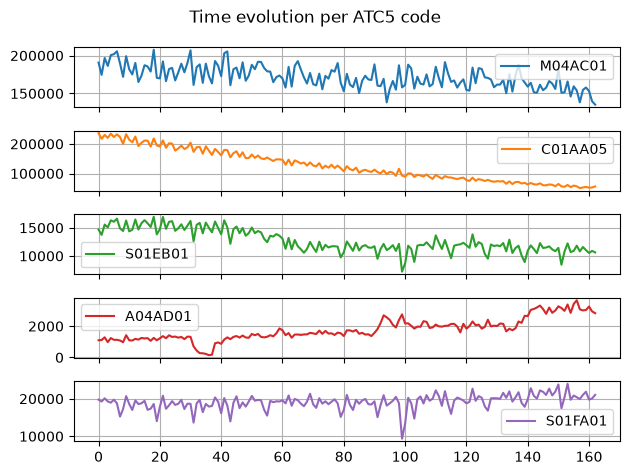

In [7]:
train_data.plot(
    subplots=True, 
    title="Time evolution per ATC5 code",
    grid=True,
)
plt.tight_layout()
plt.show()

In [8]:
models = {}
forecasts = {}

for code in codes:
    print(f"\n===== SARIMA training for ATC5: {code} =====")
    start_time = time.perf_counter()
    model = pm.auto_arima(
        train_data[code],
        seasonal=True,
        m=12, # 12 months per year
        d=1, D=1, # differetiation for stability and seasonality
        trace=False,
        error_action="ignore",
        suppress_warnings=True,
        stepwise=True,
    )
    end_time = time.perf_counter()
    print(f"Training took: {(end_time-start_time):.2f} seconds")
    models[code] = model
    forecasts[code] = model.predict(n_periods=TEST_MONTHS)
    print(f"Best model: {model.order} x {model.seasonal_order}")


===== SARIMA training for ATC5: M04AC01 =====
Training took: 8.17 seconds
Best model: (1, 1, 0) x (0, 1, 2, 12)

===== SARIMA training for ATC5: C01AA05 =====
Training took: 3.47 seconds
Best model: (0, 1, 1) x (0, 1, 0, 12)

===== SARIMA training for ATC5: S01EB01 =====
Training took: 57.97 seconds
Best model: (3, 1, 3) x (1, 1, 2, 12)

===== SARIMA training for ATC5: A04AD01 =====
Training took: 12.97 seconds
Best model: (1, 1, 1) x (0, 1, 1, 12)

===== SARIMA training for ATC5: S01FA01 =====
Training took: 6.48 seconds
Best model: (0, 1, 1) x (0, 1, 1, 12)


In [9]:
for code in codes:
    y_true = test_data[code]
    y_pred = forecasts[code]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

    print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

ATC5: M04AC01 | RMSE: 15869.64 | MAPE: 13.37%
ATC5: C01AA05 | RMSE: 2963.84 | MAPE: 4.20%
ATC5: S01EB01 | RMSE: 350.78 | MAPE: 2.85%
ATC5: A04AD01 | RMSE: 630.16 | MAPE: 25.64%
ATC5: S01FA01 | RMSE: 1869.32 | MAPE: 8.76%


The models for 'C01AA05', 'S01EB01', 'S01FA01' are good enough.

The models for 'M04AC01', 'A04AD01' look bad. Let's plot the whole dataset and the predictions to gain insights 

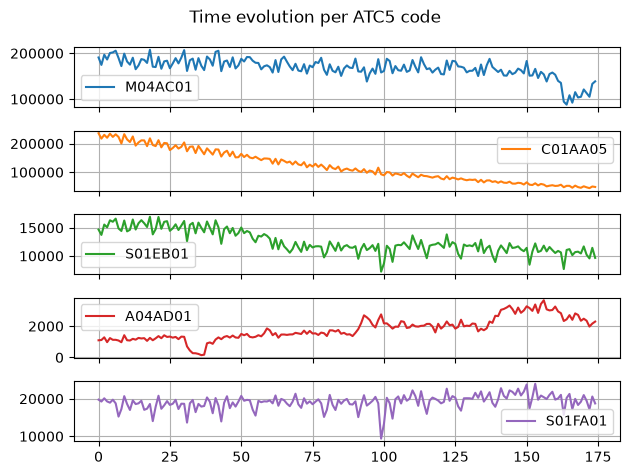

In [10]:
data.plot(
    subplots=True, 
    title="Time evolution per ATC5 code",
    grid=True,
)
plt.tight_layout()
plt.show()

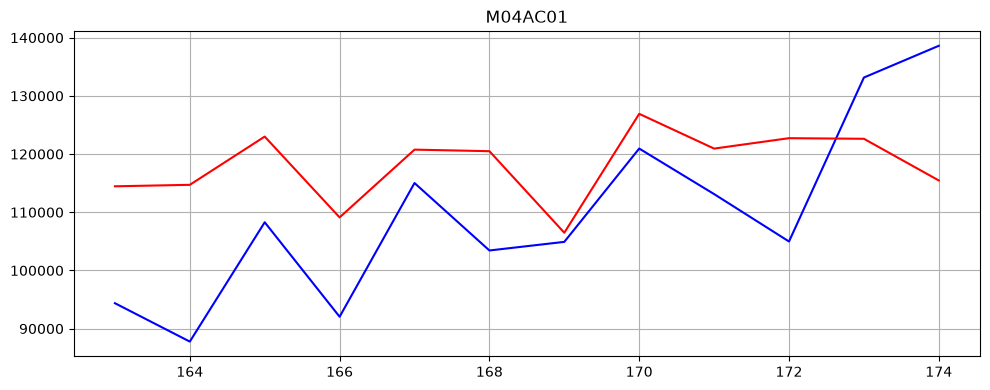

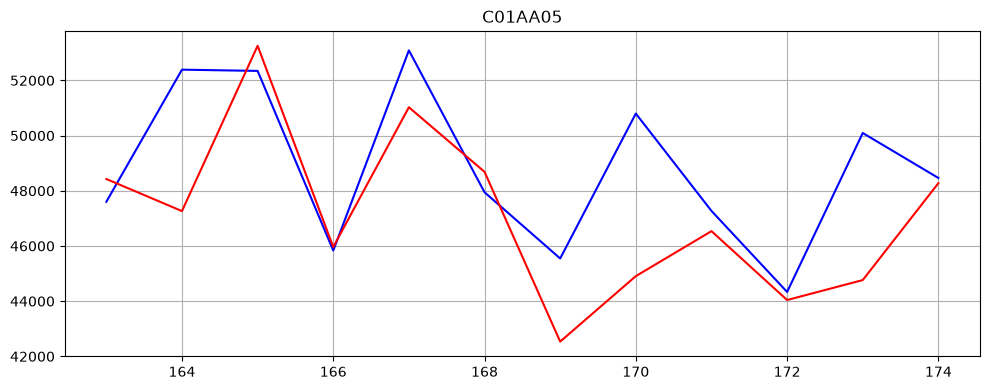

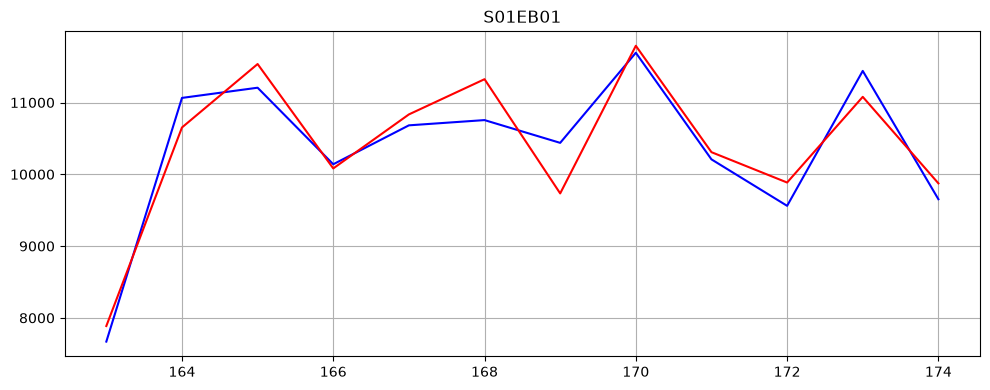

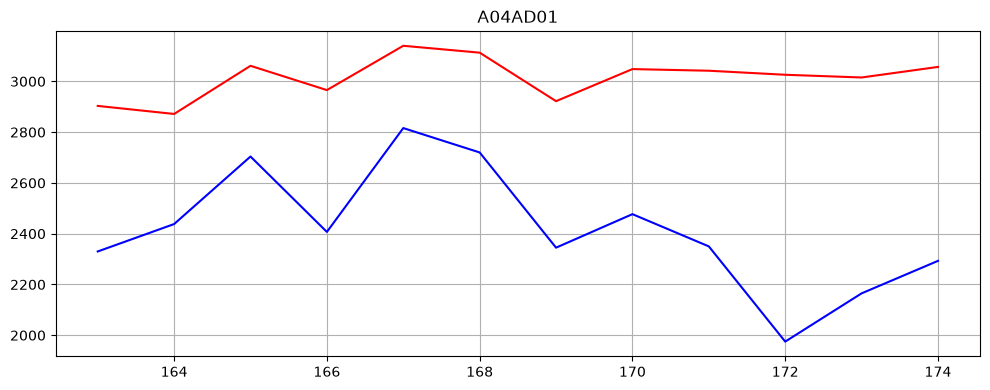

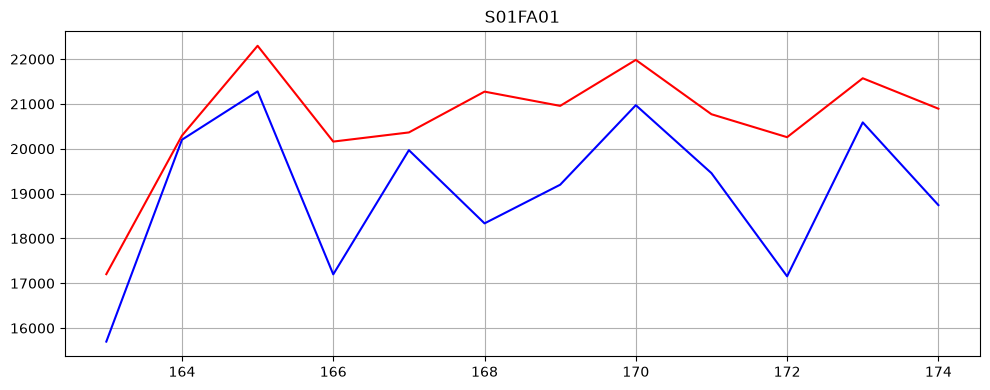

In [11]:
forecast_df = pd.DataFrame(forecasts)

for code in codes:
    plt.figure(figsize=(10,4))
    plt.plot(test_data[code], "b")
    plt.plot(forecast_df[code], "r")
    plt.title(code)
    plt.grid()
    plt.tight_layout()
    plt.show()

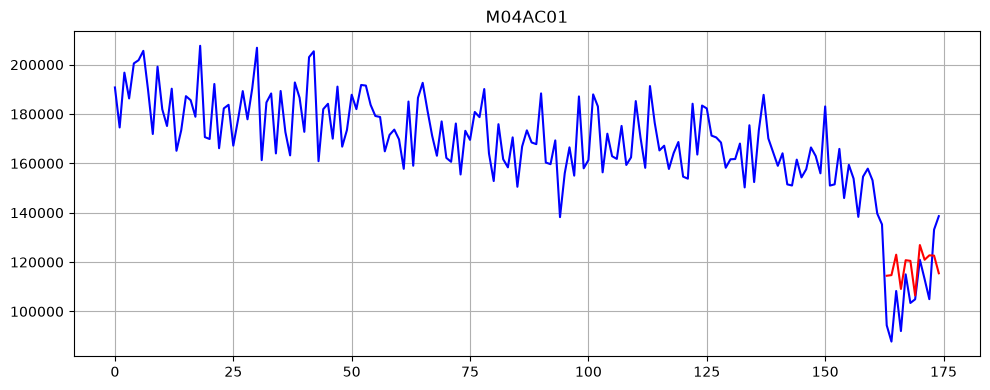

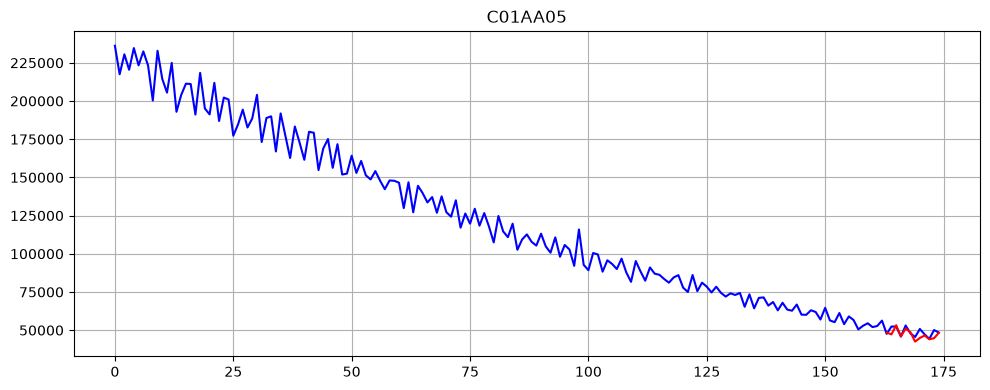

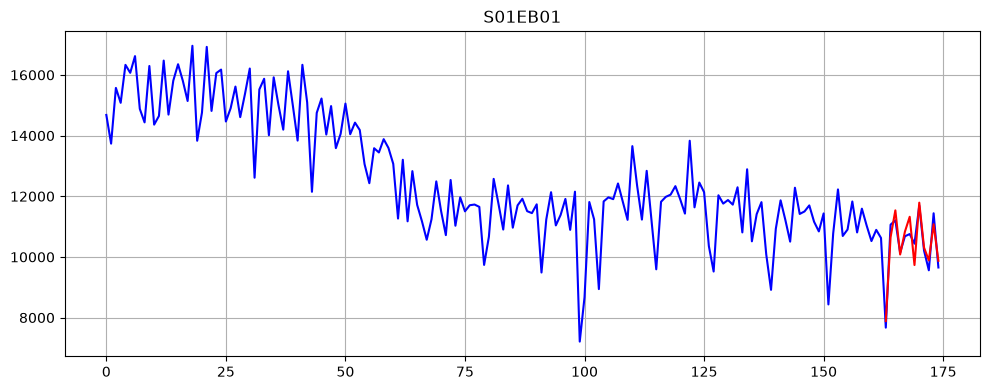

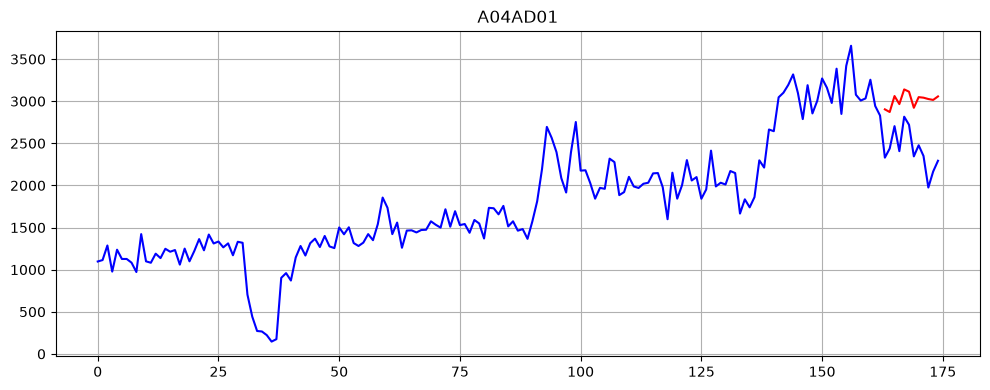

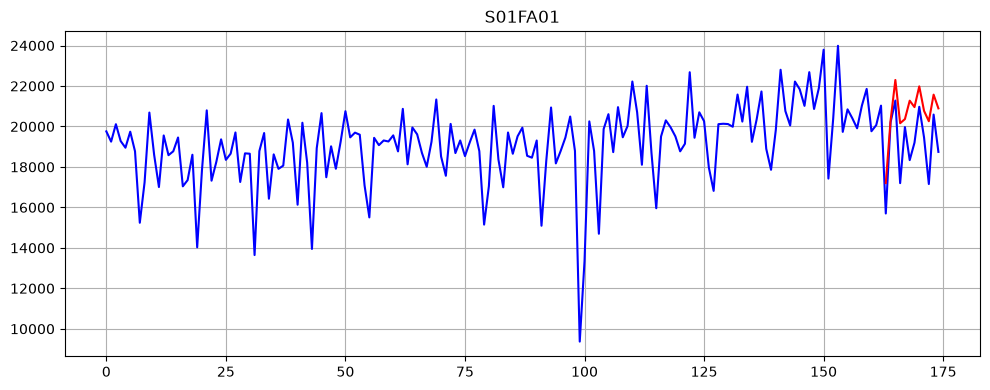

In [12]:
for code in codes:
    plt.figure(figsize=(10,4))
    plt.plot(data[code], "b")
    plt.plot(forecast_df[code], "r")
    plt.title(code)
    plt.grid()
    plt.tight_layout()
    plt.show()

After all, the models seem good enough despite the mid metrics! The 3 models with the very good metrics seem excellent. 

The 2 models with the bad metrics were just tested with unexpected test data. The model for M04AC01 is ok. The model for A04AD01 isn't that good because the data changed vastly. This might have happened due to unpredictable exogenous reasons such as:
- Regulatory decisions: The state decided to change the reimbursement rate for the medication.
- Supply chain: A stockout occurred—either for the medication itself or for a competitor—leading everyone to purchase A04AD01 as a substitute.
- Entry of a generic drug: A cheaper version of the medication was launched, capturing some of its market share.

Unfortunately, there's not a lot we can do about this score and it seems to be a limitation of the project.

### Final training and saving

In [13]:
final_models = {}
final_forecasts = {}

for code in codes:
    print(f"\n==== Final model training on whole dataset for: {code} ====")

    best_order = models[code].order
    best_seasonal_order = models[code].seasonal_order
    
    start_time = time.perf_counter()
    
    final_model = pm.ARIMA(
        order=best_order,
        seasonal_order=best_seasonal_order,
        suppress_warnings=True,
    )

    final_model.fit(data[code])
    final_models[code] = final_model

    final_forecasts[code] = final_model.predict(n_periods=12)

    end_time = time.perf_counter()
    print(f"Training took: {(end_time-start_time):.2f} seconds")

    model_path = MODELS_DIR / Path(f"sarima_{code}.joblib")
    joblib.dump(final_model, model_path)

    print(f"Best parameters: {best_order} x {best_seasonal_order}")
    print(f"Saved at: {model_path}\n")

output_path = OUTPUT_DATA_DIR / Path("forecast_in_boxes_12_months.csv")
pd.DataFrame(final_forecasts).to_csv(output_path, index=False)
print(f"Forecast saved at: {output_path}")


==== Final model training on whole dataset for: M04AC01 ====
Training took: 0.38 seconds
Best parameters: (1, 1, 0) x (0, 1, 2, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_M04AC01.joblib


==== Final model training on whole dataset for: C01AA05 ====
Training took: 0.16 seconds
Best parameters: (0, 1, 1) x (0, 1, 0, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_C01AA05.joblib


==== Final model training on whole dataset for: S01EB01 ====
Training took: 2.94 seconds
Best parameters: (3, 1, 3) x (1, 1, 2, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_S01EB01.joblib


==== Final model training on whole dataset for: A04AD01 ====
Training took: 0.68 seconds
Best parameters: (1, 1, 1) x (0, 1, 1, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_Ethno

### Expansion with 3 more ATC5 codes

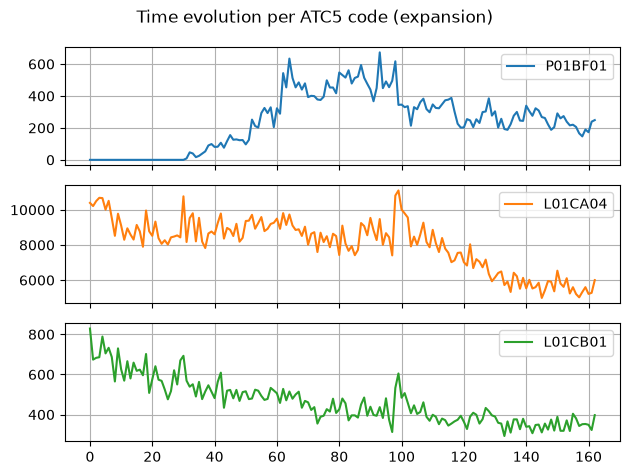

In [14]:
data_expansion = pd.read_csv(PROCESSED_DATA_DIR / Path("expanded_train_data.csv"))
data_expansion = data_expansion[EXPANSION]
train_data_exp = data_expansion.iloc[:TRAIN_MONTHS]
test_data_exp = data_expansion.iloc[TRAIN_MONTHS:]
train_data_exp.plot(
    subplots=True, 
    title="Time evolution per ATC5 code (expansion)",
    grid=True,
)
plt.tight_layout()
plt.show()

Train like before for the data without na values

In [15]:
for code in EXPANSION[1:]:
    print(f"\n===== SARIMA training for ATC5: {code} =====")
    start_time = time.perf_counter()
    model = pm.auto_arima(
        train_data_exp[code],
        seasonal=True,
        m=12, # 12 months per year
        d=1, D=1, # differetiation for stability and seasonality
        trace=False,
        error_action="ignore",
        suppress_warnings=True,
        stepwise=True,
    )
    end_time = time.perf_counter()
    print(f"Training took: {(end_time-start_time):.2f} seconds")
    models[code] = model
    forecasts[code] = model.predict(n_periods=TEST_MONTHS)
    print(f"Best model: {model.order} x {model.seasonal_order}")


===== SARIMA training for ATC5: L01CA04 =====
Training took: 25.27 seconds
Best model: (2, 1, 1) x (0, 1, 1, 12)

===== SARIMA training for ATC5: L01CB01 =====
Training took: 11.12 seconds
Best model: (0, 1, 1) x (0, 1, 1, 12)


In [16]:
P01BF01_data = train_data_exp[EXPANSION[0]]
P01BF01_data = P01BF01_data.dropna()
first_active_month = P01BF01_data[P01BF01_data > 0].index[0]
P01BF01_data = P01BF01_data[first_active_month:]
print(f"First active month: {first_active_month}")

First active month: 31


In [17]:
code = "P01BF01"
print(f"\n===== SARIMA training for ATC5: {code} =====")
start_time = time.perf_counter()
model = pm.auto_arima(
    P01BF01_data,
    seasonal=True,
    m=12, # 12 months per year
    d=1, D=1, # differetiation for stability and seasonality
    trace=False,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
)
end_time = time.perf_counter()
print(f"Training took: {(end_time-start_time):.2f} seconds")
models[code] = model
forecasts[code] = model.predict(n_periods=TEST_MONTHS)
print(f"Best model: {model.order} x {model.seasonal_order}")


===== SARIMA training for ATC5: P01BF01 =====
Training took: 5.47 seconds
Best model: (1, 1, 0) x (2, 1, 0, 12)


In [18]:
for code in EXPANSION:
    y_true = test_data_exp[code]
    y_pred = forecasts[code]

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

    print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

ATC5: P01BF01 | RMSE: 44.78 | MAPE: 21.88%
ATC5: L01CA04 | RMSE: 484.43 | MAPE: 7.21%
ATC5: L01CB01 | RMSE: 74.12 | MAPE: 24.58%


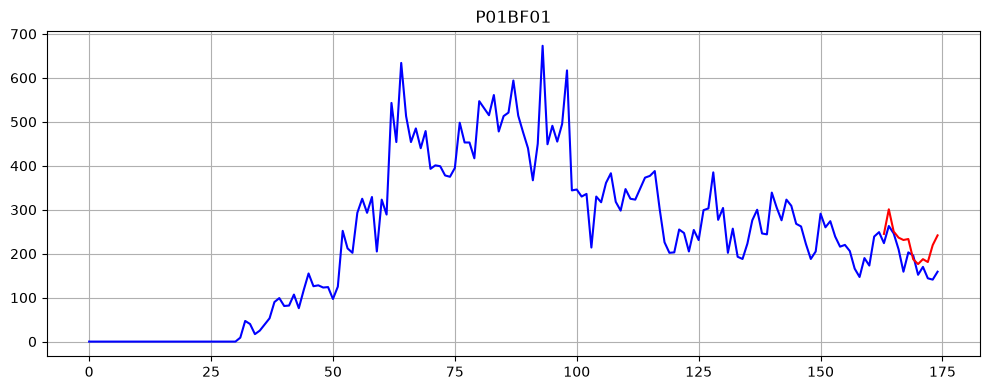

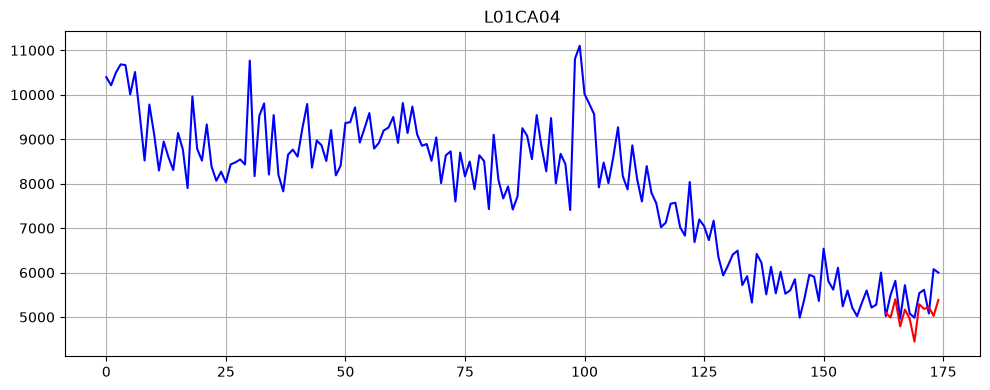

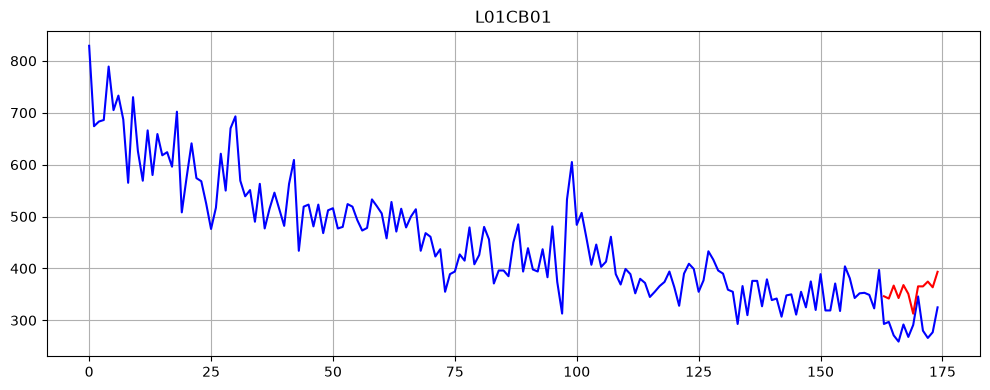

In [19]:
forecast_df = pd.DataFrame(forecasts)

for code in EXPANSION:
    plt.figure(figsize=(10,4))
    plt.plot(data_expansion[code], "b")
    plt.plot(forecast_df[code], "r")
    plt.title(code)
    plt.grid()
    plt.tight_layout()
    plt.show()

We see that for code L01CB01 until month ~100 there is a steady decline and after that a stabilization. Let's train again the arima with more recent data to fit with stabilization.


===== SARIMA training for ATC5: L01CB01 =====
Training took: 7.33 seconds
Best model: (0, 1, 1) x (0, 1, 1, 12)
ATC5: L01CB01 | RMSE: 98.37 | MAPE: 33.55%


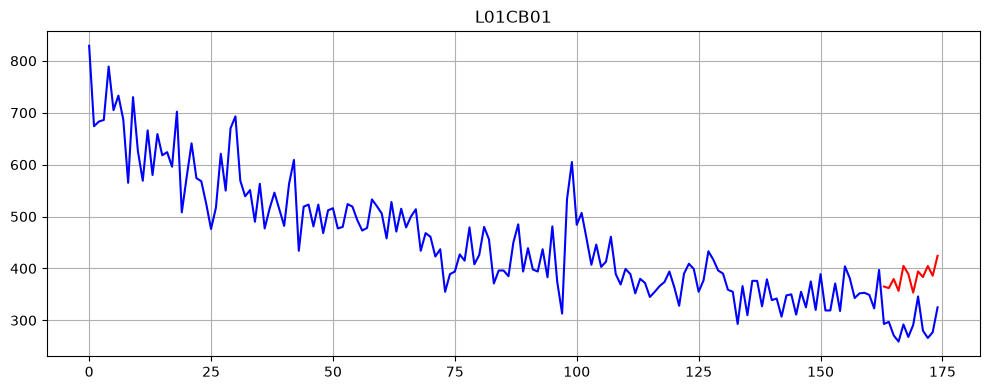

In [20]:
code = "L01CB01"
print(f"\n===== SARIMA training for ATC5: {code} =====")
start_time = time.perf_counter()
model = pm.auto_arima(
    train_data_exp[code][100:],
    seasonal=True,
    m=12, # 12 months per year
    d=1, D=1, # differetiation for stability and seasonality
    trace=False,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
)
end_time = time.perf_counter()
print(f"Training took: {(end_time-start_time):.2f} seconds")
key = f"{code}_new" 
models[key] = model
forecasts[key] = model.predict(n_periods=TEST_MONTHS)
print(f"Best model: {model.order} x {model.seasonal_order}")

y_true = test_data_exp[code]
y_pred = forecasts[key]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

forecast_df = pd.DataFrame(forecasts)

plt.figure(figsize=(10,4))
plt.plot(data_expansion[code], "b")
plt.plot(forecast_df[key], "r")
plt.title(code)
plt.grid()
plt.tight_layout()
plt.show()

Well that didn't work. Let's try log transform


===== SARIMA training for ATC5: L01CB01 =====
Training took: 24.30 seconds
Best model: (0, 1, 1) x (2, 1, 0, 12)
ATC5: L01CB01 | RMSE: 70.08 | MAPE: 23.12%


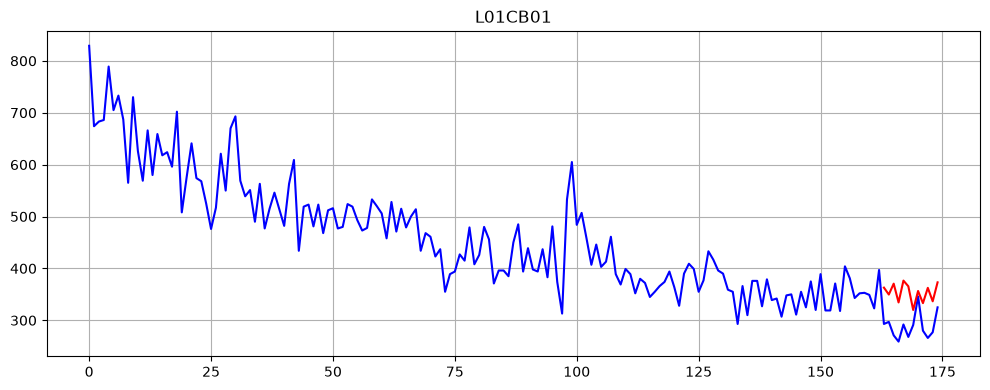

In [21]:
code = "L01CB01"
log_data = np.log(train_data_exp[code])
print(f"\n===== SARIMA training for ATC5: {code} =====")
start_time = time.perf_counter()
model = pm.auto_arima(
    log_data,
    seasonal=True,
    m=12, # 12 months per year
    d=1, D=1, # differetiation for stability and seasonality
    trace=False,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
)
end_time = time.perf_counter()
print(f"Training took: {(end_time-start_time):.2f} seconds")
key = f"{code}_new" 
models[key] = model
forecasts[key] = np.exp(model.predict(n_periods=TEST_MONTHS))
print(f"Best model: {model.order} x {model.seasonal_order}")

y_true = test_data_exp[code]
y_pred = forecasts[key]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

forecast_df = pd.DataFrame(forecasts)

plt.figure(figsize=(10,4))
plt.plot(data_expansion[code], "b")
plt.plot(forecast_df[key], "r")
plt.title(code)
plt.grid()
plt.tight_layout()
plt.show()

Only minor improvement. We see an outlier right before month 100. What if we clean it?


===== SARIMA training for ATC5: L01CB01 =====
Training took: 8.74 seconds
Best model: (0, 1, 1) x (0, 1, 2, 12)
ATC5: L01CB01 | RMSE: 55.41 | MAPE: 17.96%


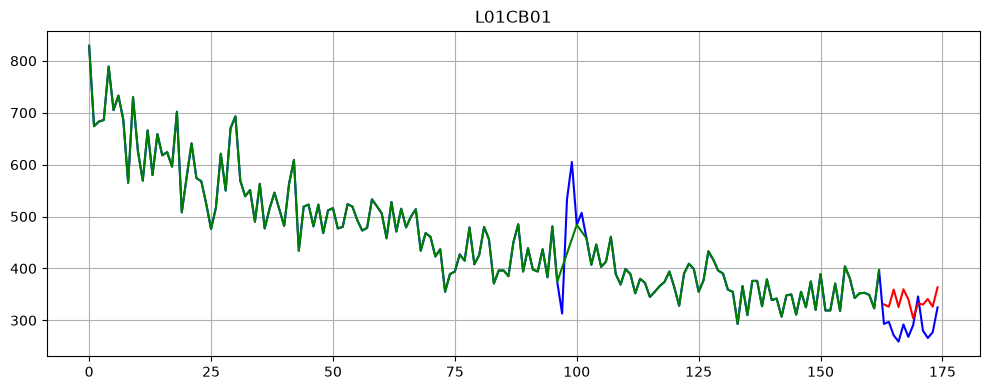

In [22]:
clean_data = train_data_exp['L01CB01'].copy()

outlier_mask = ((clean_data > 500) | (clean_data < 350)) & (clean_data.index > 95) & (clean_data.index < 102)

clean_data[outlier_mask] = np.nan

clean_data = clean_data.interpolate(method='linear')

code = "L01CB01"
print(f"\n===== SARIMA training for ATC5: {code} =====")
start_time = time.perf_counter()
model = pm.auto_arima(
    clean_data,
    seasonal=True,
    m=12, # 12 months per year
    d=1, D=1, # differetiation for stability and seasonality
    trace=False,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True,
)
end_time = time.perf_counter()
print(f"Training took: {(end_time-start_time):.2f} seconds")
key = f"{code}_new" 
models[key] = model
forecasts[key] = model.predict(n_periods=TEST_MONTHS)
print(f"Best model: {model.order} x {model.seasonal_order}")

y_true = test_data_exp[code]
y_pred = forecasts[key]

rmse = np.sqrt(mean_squared_error(y_true, y_pred))
mape = np.mean(np.abs((y_true-y_pred) / y_true)) * 100

print(f"ATC5: {code} | RMSE: {rmse:.2f} | MAPE: {mape:.2f}%")

forecast_df = pd.DataFrame(forecasts)

plt.figure(figsize=(10,4))
plt.plot(data_expansion[code], "b")
plt.plot(forecast_df[key], "r")
plt.plot(clean_data, "g")
plt.title(code)
plt.grid()
plt.tight_layout()
plt.show()

That worked! The performance is significantly better. It is not very good but it will do, because the drop we see is unexpected

In [23]:
cleaned_expansion_data = {}

# 1. P01BF01: Remove initial zeros / NaN
full_p01 = data_expansion['P01BF01'].copy().dropna()
first_active_month_p01 = full_p01[full_p01 > 0].index[0]
cleaned_expansion_data['P01BF01'] = full_p01.loc[first_active_month_p01:]

# 2. L01CB01: Outlier removal (Despiking)
full_l01cb01 = data_expansion['L01CB01'].copy()
outlier_mask = ((full_l01cb01 > 500) | (full_l01cb01 < 350)) & (full_l01cb01.index > 95) & (full_l01cb01.index < 102)
full_l01cb01[outlier_mask] = np.nan
cleaned_expansion_data['L01CB01'] = full_l01cb01.interpolate(method='linear')

# 3. L01CA04: kept as is
cleaned_expansion_data['L01CA04'] = data_expansion['L01CA04'].copy()

In [24]:
best_params_expansion = {
    'P01BF01': {'order': (1, 1, 0), 'seasonal_order': (2, 1, 0, 12)},
    'L01CA04': {'order': (2, 1, 1), 'seasonal_order': (0, 1, 1, 12)},
    'L01CB01': {'order': (0, 1, 1), 'seasonal_order': (0, 1, 2, 12)}
}

final_exp_models = {}
final_exp_forecasts = {}
STEPS_INTO_FUTURE = 12 

for code in EXPANSION:
    print(f"\n==== Final model training on whole dataset for: {code} ====")
    start_time = time.perf_counter()
    
    order = best_params_expansion[code]['order']
    seasonal_order = best_params_expansion[code]['seasonal_order']
    ts_data = cleaned_expansion_data[code]
    
    final_model = pm.ARIMA(
        order=order,
        seasonal_order=seasonal_order,
        suppress_warnings=True
    )
    
    final_model.fit(ts_data)
    
    forecast = final_model.predict(n_periods=STEPS_INTO_FUTURE)
    
    final_exp_models[code] = final_model
    final_exp_forecasts[code] = forecast
    
    end_time = time.perf_counter()
    
    model_path = MODELS_DIR / f"sarima_{code}.joblib"
    joblib.dump(final_model, model_path)
    
    print(f"Training took: {(end_time - start_time):.2f} seconds")
    print(f"Parameters: {order} x {seasonal_order}")
    print(f"Saved at: {model_path}")

df_exp_forecasts = pd.DataFrame(final_exp_forecasts)

expaneded_forecast = pd.concat([pd.DataFrame(final_forecasts), df_exp_forecasts], axis=1)

output_path = OUTPUT_DATA_DIR / "expanded_forecast_in_boxes_12_months.csv"
expaneded_forecast.to_csv(output_path, index=False)
print(f"Forecast saved at: {output_path}")


==== Final model training on whole dataset for: P01BF01 ====
Training took: 0.76 seconds
Parameters: (1, 1, 0) x (2, 1, 0, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_P01BF01.joblib

==== Final model training on whole dataset for: L01CA04 ====
Training took: 0.83 seconds
Parameters: (2, 1, 1) x (0, 1, 1, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_L01CA04.joblib

==== Final model training on whole dataset for: L01CB01 ====
Training took: 0.71 seconds
Parameters: (0, 1, 1) x (0, 1, 2, 12)
Saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\models\sarima_L01CB01.joblib
Forecast saved at: C:\Users\chris\Desktop\MyCode\ethnohack_2026\AgriPharm\AgriPharm_Track3_EthnoHack_2026\data\outputs\expanded_forecast_in_boxes_12_months.csv
